<a href="https://colab.research.google.com/github/Nyangweso1/my-portfolio/blob/main/prudence_nyangweso_wine_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wine Classification: Comparing Six Models

**Dataset:** Wine (built into scikit-learn): 178 wines from three cultivars in one Italian region, described by 13 chemical measurements.

**Goal:** Train Logistic Regression, Decision Tree, Random Forest, KNN, Naive Bayes and SVM, evaluate each one, and compare them.

**Workflow:** 1. Load → 2. EDA → 3. Prepare data → 4. Build models → 5. Evaluate → 6. Compare

## Setup
Import libraries. (Everything here is preinstalled in Google Colab.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the dataset

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")
print("Features shape:", X.shape)
print("Target shape  :", y.shape)

Features shape: (178, 13)
Target shape  : (178,)


## 2. Exploratory Data Analysis (EDA)
### 2.1 Features, target classes and data quality

In [3]:
print("Feature names:")
for i, name in enumerate(wine.feature_names, 1):
    print(f"  {i:2d}. {name}")

print("\nTarget classes:", [str(c) for c in wine.target_names])
print("\nClass counts:")
print(y.map(dict(enumerate(wine.target_names))).value_counts().sort_index())

print("\nMissing values per column:", int(X.isna().sum().sum()), "(total)")
print("Data types:", X.dtypes.unique())

Feature names:
   1. alcohol
   2. malic_acid
   3. ash
   4. alcalinity_of_ash
   5. magnesium
   6. total_phenols
   7. flavanoids
   8. nonflavanoid_phenols
   9. proanthocyanins
  10. color_intensity
  11. hue
  12. od280/od315_of_diluted_wines
  13. proline

Target classes: ['class_0', 'class_1', 'class_2']

Class counts:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

Missing values per column: 0 (total)
Data types: [dtype('float64')]


### 2.2 First rows and summary statistics

In [4]:
display(X.head())
display(X.describe().T.round(2))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


### 2.3 Visual exploration
The boxplot shows that features sit on very different scales (e.g. `proline` is in the hundreds/thousands while `hue` is around 1). That matters for distance-based and gradient-based models, so we scale later.

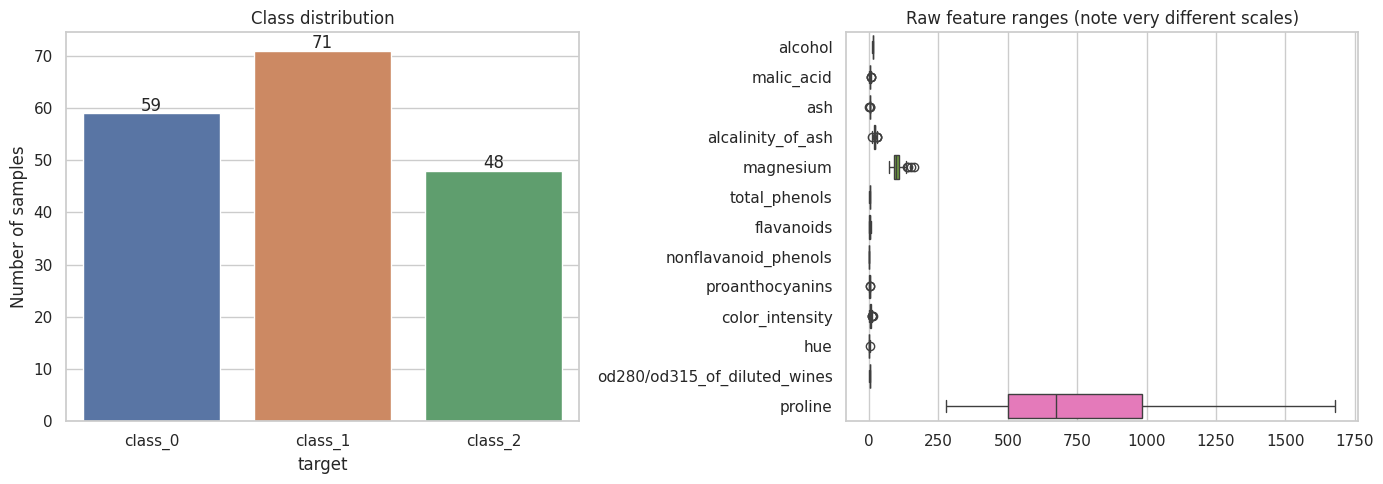

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
counts = y.map(dict(enumerate(wine.target_names))).value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=axes[0])
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Number of samples")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 0.5, str(v), ha="center")

# Feature scale differences
sns.boxplot(data=X, orient="h", ax=axes[1])
axes[1].set_title("Raw feature ranges (note very different scales)")
plt.tight_layout()
plt.show()

### 2.4 Correlations and class differences

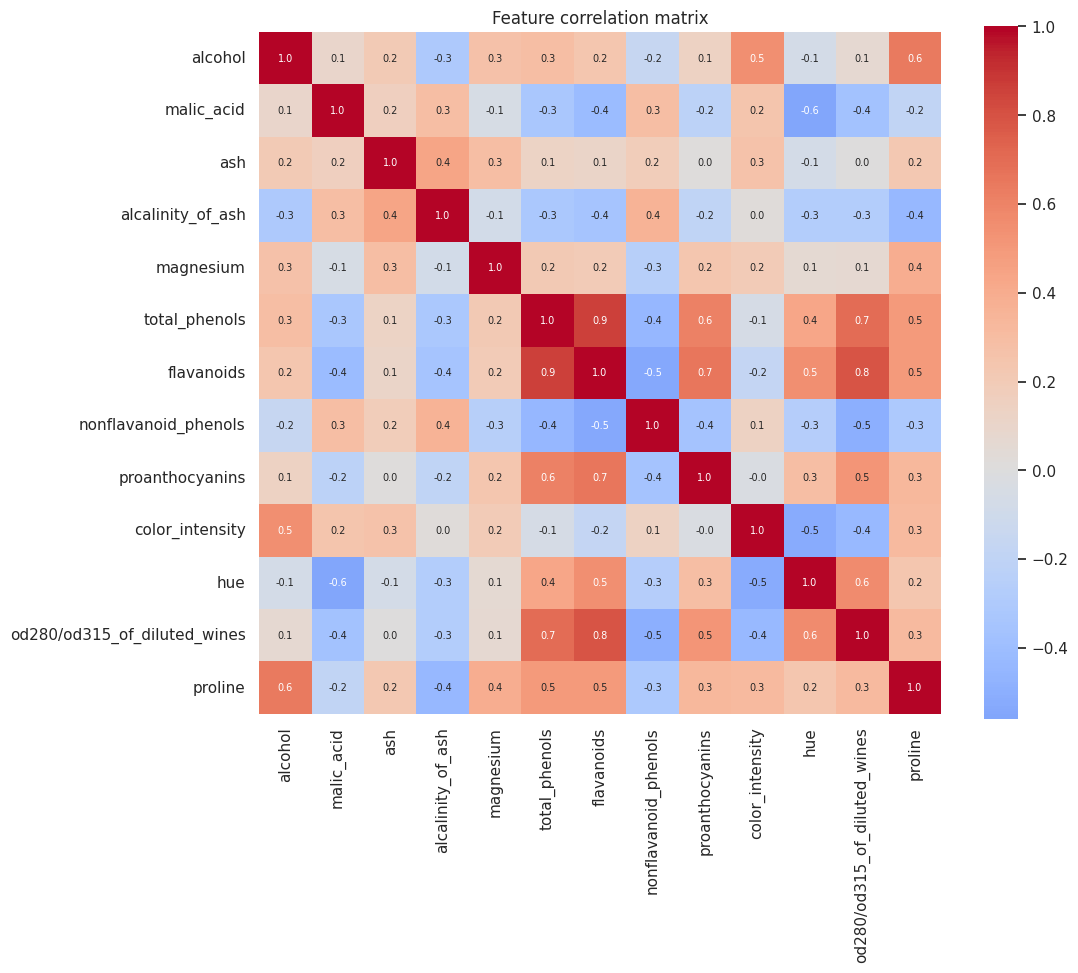

class,class_0,class_1,class_2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


In [6]:
plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, square=True)
plt.title("Feature correlation matrix")
plt.show()

# Which features differ most between classes?
df = X.copy()
df["class"] = y.map(dict(enumerate(wine.target_names)))
display(df.groupby("class").mean().T.round(2))

### 2.5 How the key features separate the classes

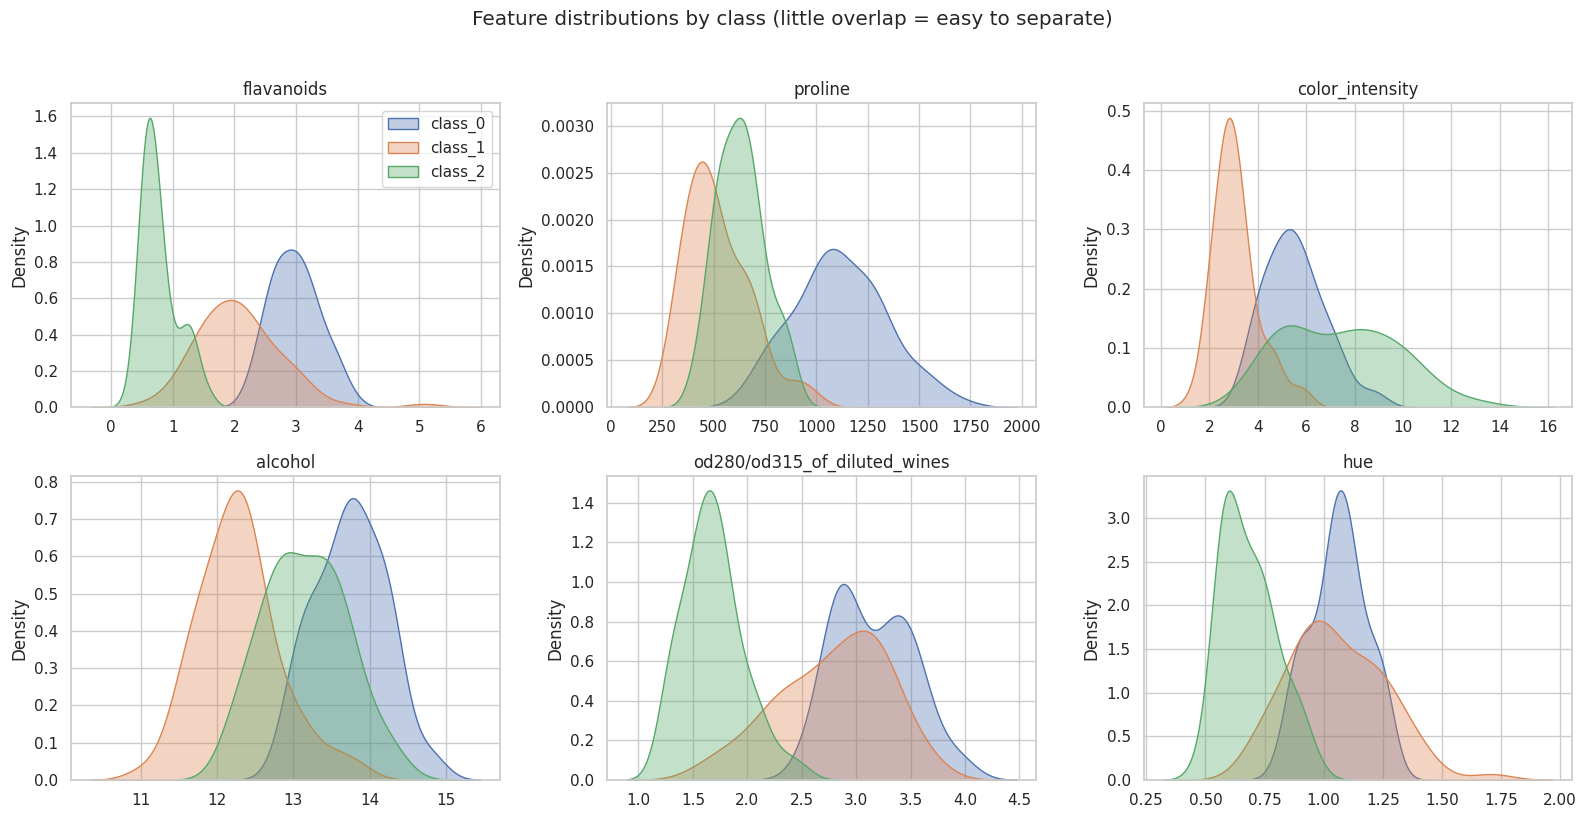

In [7]:
key_feats = ["flavanoids", "proline", "color_intensity", "alcohol", "od280/od315_of_diluted_wines", "hue"]
class_names = [str(c) for c in wine.target_names]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, f in zip(axes.ravel(), key_feats):
    for k, cname in enumerate(class_names):
        sns.kdeplot(X.loc[y == k, f], ax=ax, label=cname, fill=True, alpha=0.35)
    ax.set_title(f)
    ax.set_xlabel("")
axes[0, 0].legend()
plt.suptitle("Feature distributions by class (little overlap = easy to separate)", y=1.02)
plt.tight_layout()
plt.show()

### 2.6 Pairplot of the four most informative features

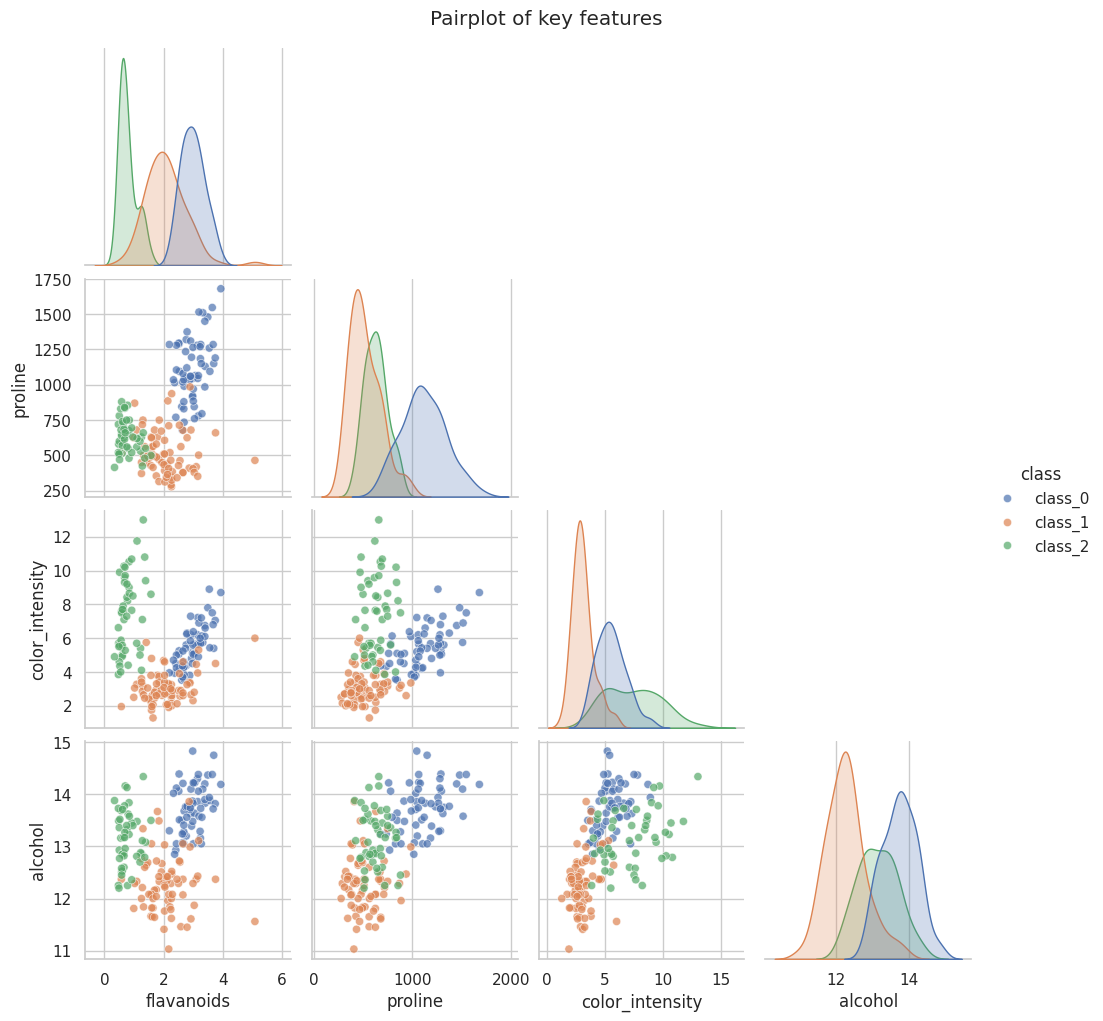

In [8]:
pp_df = X[["flavanoids", "proline", "color_intensity", "alcohol"]].copy()
pp_df["class"] = y.map(dict(enumerate(class_names)))
sns.pairplot(pp_df, hue="class", corner=True, plot_kws={"alpha": 0.7, "s": 35})
plt.suptitle("Pairplot of key features", y=1.02)
plt.show()

### 2.7 PCA: all 13 features squeezed into 2 dimensions
This shows that the three classes form fairly distinct clusters even in just two dimensions.

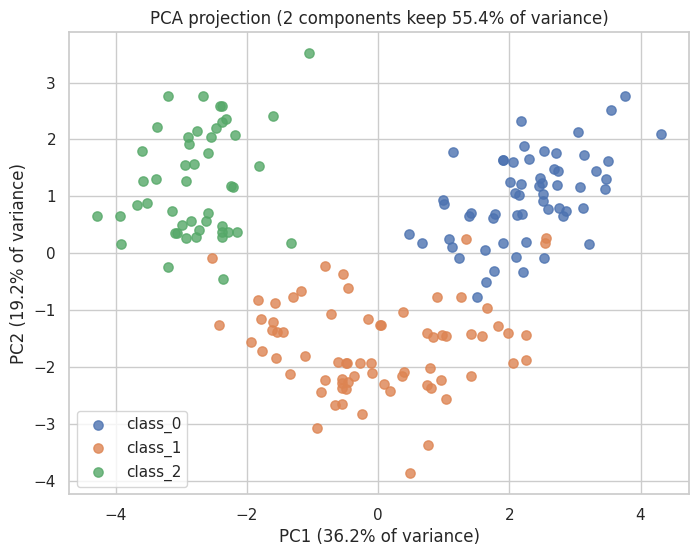

In [9]:
from sklearn.decomposition import PCA

X_all_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2).fit(X_all_scaled)
X_pca = pca.transform(X_all_scaled)
ev = pca.explained_variance_ratio_

plt.figure(figsize=(8, 6))
for k, cname in enumerate(class_names):
    plt.scatter(X_pca[y == k, 0], X_pca[y == k, 1], label=cname, alpha=0.8, s=45)
plt.xlabel(f"PC1 ({ev[0]*100:.1f}% of variance)")
plt.ylabel(f"PC2 ({ev[1]*100:.1f}% of variance)")
plt.title(f"PCA projection (2 components keep {ev.sum()*100:.1f}% of variance)")
plt.legend()
plt.show()

**EDA takeaways**
- 178 samples, 13 numeric features, **no missing values**.
- Three classes, mildly imbalanced (59 / 71 / 48), so we use a *stratified* split.
- Feature scales vary enormously → scaling is needed for Logistic Regression, KNN, SVM (and is harmless for Naive Bayes).
- Features such as `flavanoids`, `proline`, `color_intensity` and `alcohol` differ strongly between classes, so the classes should be quite separable.
- Several features are correlated (e.g. `flavanoids` with `total_phenols`), which can hurt models that assume independence (Naive Bayes) but is handled fine by regularised models.

## 3. Prepare the data
- 80/20 **stratified** train/test split (keeps class proportions the same in both sets).
- `StandardScaler` is **fitted on the training set only** and then applied to the test set, to avoid data leakage.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)
print("Train class proportions:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test class proportions :", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

# Scale using statistics from the TRAINING set only (avoids data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train size: (142, 13)  Test size: (36, 13)
Train class proportions: {0: 0.331, 1: 0.401, 2: 0.268}
Test class proportions : {0: 0.333, 1: 0.389, 2: 0.278}


## 4. Build the six models
Models that depend on distances or gradients (Logistic Regression, KNN, SVM, Naive Bayes) use the scaled features. Decision Tree and Random Forest split on thresholds, so scaling makes no difference and they use the raw features.

In [11]:
# needs_scaling = True for distance / gradient based models.
# Trees and Random Forest are scale-invariant, so they use the raw features.
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    "Decision Tree":       (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), False),
    "KNN":                 (KNeighborsClassifier(n_neighbors=5), True),
    "Naive Bayes":         (GaussianNB(), True),
    "SVM":                 (SVC(kernel="rbf", random_state=RANDOM_STATE), True),
}

predictions = {}
for name, (model, needs_scaling) in models.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled if needs_scaling else X_test
    model.fit(Xtr, y_train)
    predictions[name] = model.predict(Xte)
    print(f"Trained: {name:20s} (scaled features: {needs_scaling})")

Trained: Logistic Regression  (scaled features: True)
Trained: Decision Tree        (scaled features: False)
Trained: Random Forest        (scaled features: False)
Trained: KNN                  (scaled features: True)
Trained: Naive Bayes          (scaled features: True)
Trained: SVM                  (scaled features: True)


## 5. Evaluate each model
For every model: accuracy, classification report (precision / recall / F1) and a confusion matrix.

Logistic Regression   |   Accuracy: 0.9722
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        12
     class_1      0.933     1.000     0.966        14
     class_2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36

Confusion matrix (rows = actual, columns = predicted):
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]] 

Decision Tree   |   Accuracy: 0.9444
              precision    recall  f1-score   support

     class_0      1.000     0.917     0.957        12
     class_1      0.875     1.000     0.933        14
     class_2      1.000     0.900     0.947        10

    accuracy                          0.944        36
   macro avg      0.958     0.939     0.946        36
weighted avg      0.951     0.944     0.945        36

Confusion matrix (rows = actual, columns = predicted):
[[11  1  

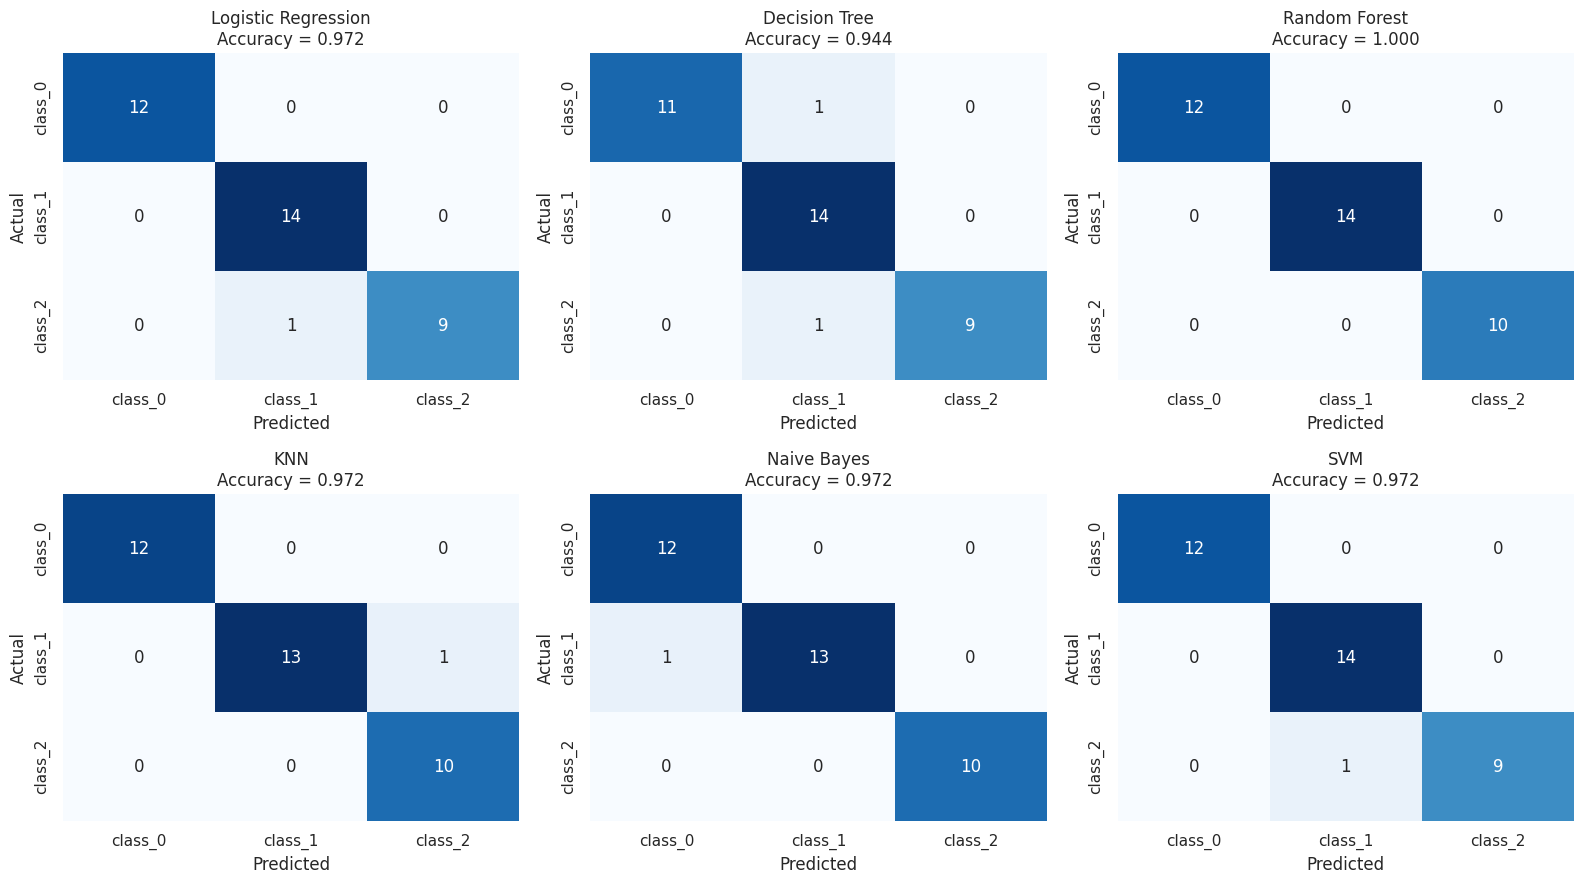

In [12]:
results = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print("=" * 62)
    print(f"{name}   |   Accuracy: {acc:.4f}")
    print("=" * 62)
    print(classification_report(y_test, y_pred, target_names=wine.target_names, digits=3))

    cm = confusion_matrix(y_test, y_pred)
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(cm, "\n")

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=wine.target_names, yticklabels=wine.target_names)
    ax.set_title(f"{name}\nAccuracy = {acc:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### 5.1 Per-class F1-score across all models
Shows at a glance which model struggles with which class (darker = better).

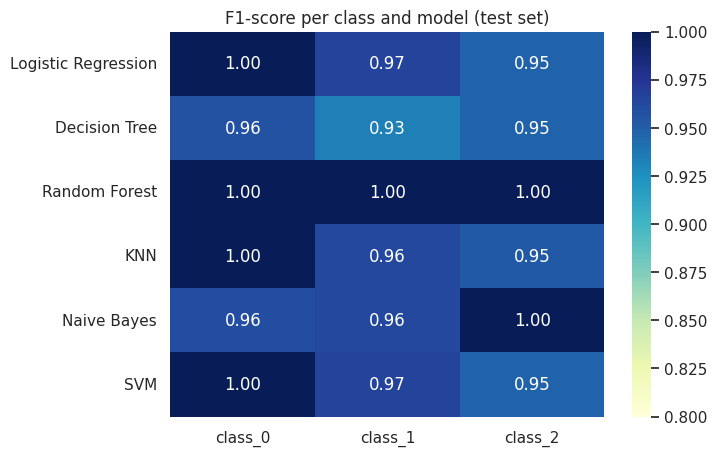

In [13]:
f1_table = {}
for name, y_pred in predictions.items():
    rep = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
    f1_table[name] = {c: rep[c]["f1-score"] for c in class_names}
f1_df = pd.DataFrame(f1_table).T

plt.figure(figsize=(7, 5))
sns.heatmap(f1_df, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.8, vmax=1.0)
plt.title("F1-score per class and model (test set)")
plt.show()

### 5.2 Macro precision, recall and F1 per model

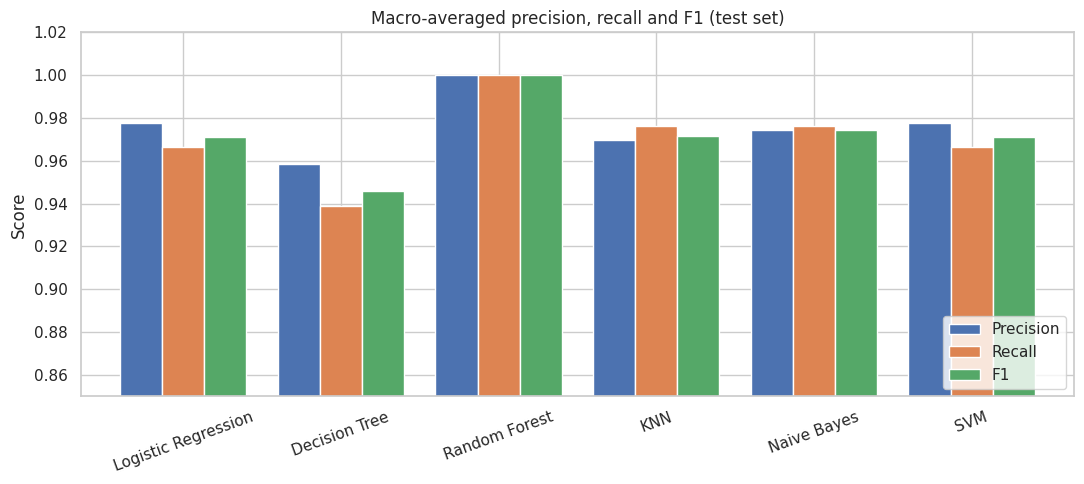

In [14]:
from sklearn.metrics import precision_recall_fscore_support
rows = {}
for name, y_pred in predictions.items():
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    rows[name] = {"Precision": p, "Recall": r, "F1": f}
prf = pd.DataFrame(rows).T
ax = prf.plot.bar(figsize=(11, 5), width=0.8)
ax.set_ylim(0.85, 1.02)
ax.set_title("Macro-averaged precision, recall and F1 (test set)")
ax.set_ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 5.3 The Decision Tree, visualised
The first splits show which chemical features separate the cultivars (top 3 levels shown).

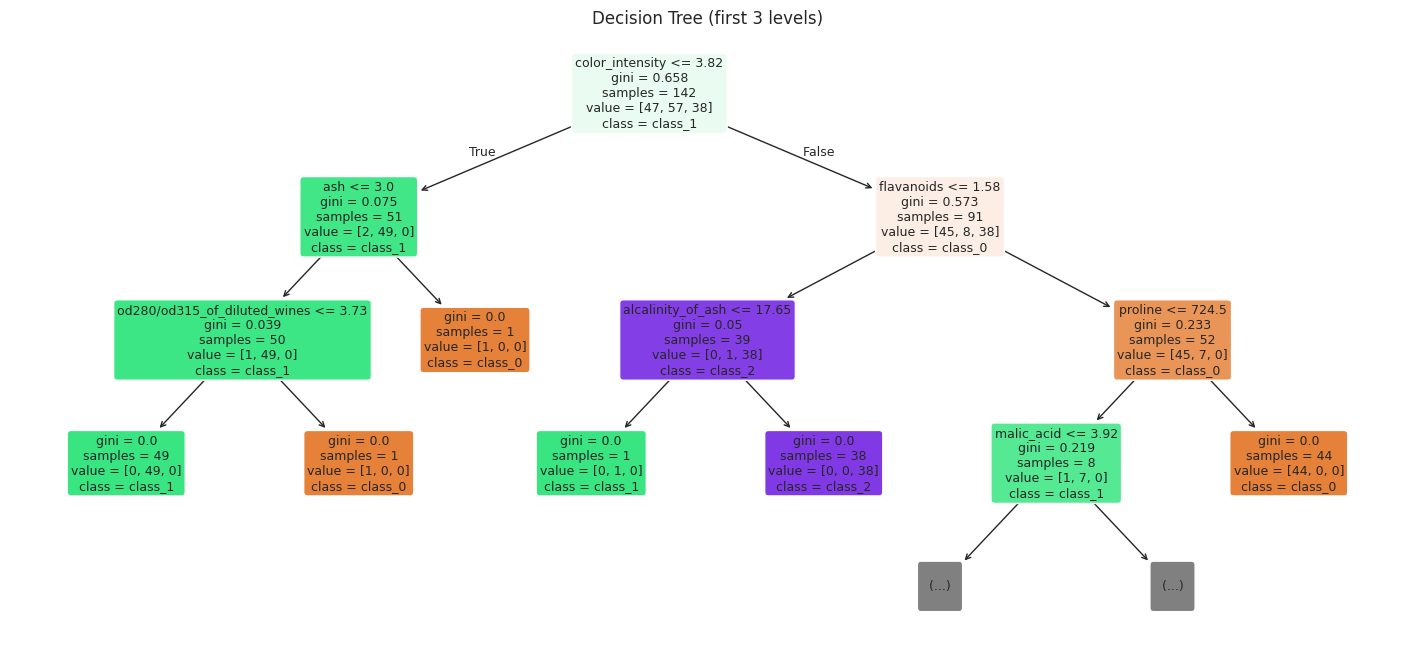

In [15]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18, 8))
plot_tree(models["Decision Tree"][0], feature_names=wine.feature_names, class_names=class_names,
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Decision Tree (first 3 levels)")
plt.show()

## 6. Compare the models
The test set is small (36 samples), so a single misclassified wine moves accuracy by about 2.8 percentage points. To avoid judging models on one lucky or unlucky split, we also run **5-fold cross-validation** on all 178 samples (scaling is done inside each fold with a pipeline, so there is no leakage).

,Test accuracy,CV mean accuracy,CV std
Logistic Regression,0.9722,0.9833,0.0136
SVM,0.9722,0.9833,0.0222
Naive Bayes,0.9722,0.9775,0.0276
Random Forest,1.0000,0.9775,0.0213
KNN,0.9722,0.9717,0.0181
Decision Tree,0.9444,0.8932,0.0380


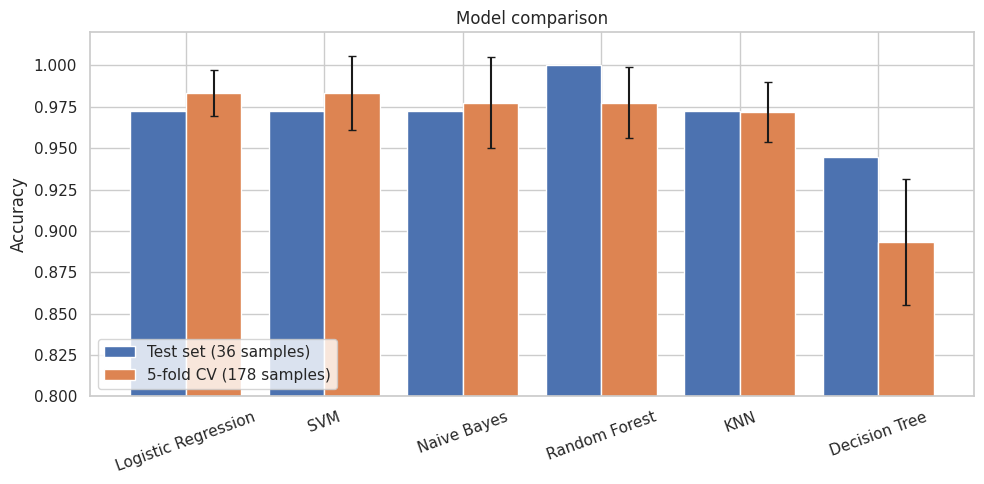

Best model by cross-validated accuracy: Logistic Regression (0.9833)


In [16]:
# The test set has only 36 samples, so one mistake changes accuracy by ~2.8 points.
# 5-fold cross-validation on all 178 samples gives a steadier comparison.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, (model, needs_scaling) in models.items():
    est = make_pipeline(StandardScaler(), model) if needs_scaling else model
    scores = cross_val_score(est, X, y, cv=cv, scoring="accuracy")
    cv_scores[name] = scores

summary = pd.DataFrame({
    "Test accuracy": pd.Series(results),
    "CV mean accuracy": {k: v.mean() for k, v in cv_scores.items()},
    "CV std": {k: v.std() for k, v in cv_scores.items()},
}).sort_values("CV mean accuracy", ascending=False)

display(summary.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
order = summary.index
x = np.arange(len(order))
ax.bar(x - 0.2, summary["Test accuracy"], width=0.4, label="Test set (36 samples)")
ax.bar(x + 0.2, summary["CV mean accuracy"], width=0.4, yerr=summary["CV std"],
       capsize=3, label="5-fold CV (178 samples)")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=20)
ax.set_ylim(0.8, 1.02)
ax.set_ylabel("Accuracy")
ax.set_title("Model comparison")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

best = summary.index[0]
print(f"Best model by cross-validated accuracy: {best} ({summary.loc[best, 'CV mean accuracy']:.4f})")

### 6.1 Cross-validation spread
Each dot is one fold. Wider boxes mean less stable performance. Note how far the Decision Tree falls behind and how much it varies.

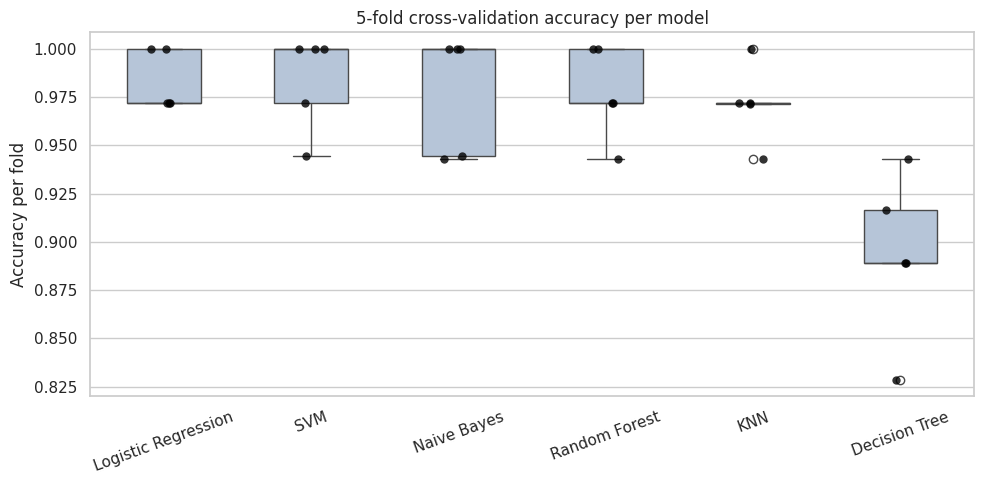

In [17]:
cv_df = pd.DataFrame(cv_scores)[summary.index]
plt.figure(figsize=(10, 5))
sns.boxplot(data=cv_df, color="lightsteelblue", width=0.5)
sns.stripplot(data=cv_df, color="black", size=6, alpha=0.8)
plt.ylabel("Accuracy per fold")
plt.title("5-fold cross-validation accuracy per model")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 6.2 Decision boundaries (illustration only)
To *see* how each algorithm separates the classes, we refit every model on just the two PCA components from section 2.7. These 2-D models are for visualisation only; they are **not** the models evaluated above, which use all 13 features. Smooth boundaries (Logistic Regression, SVM) versus blocky ones (Decision Tree, Random Forest) show the difference in how each algorithm thinks.

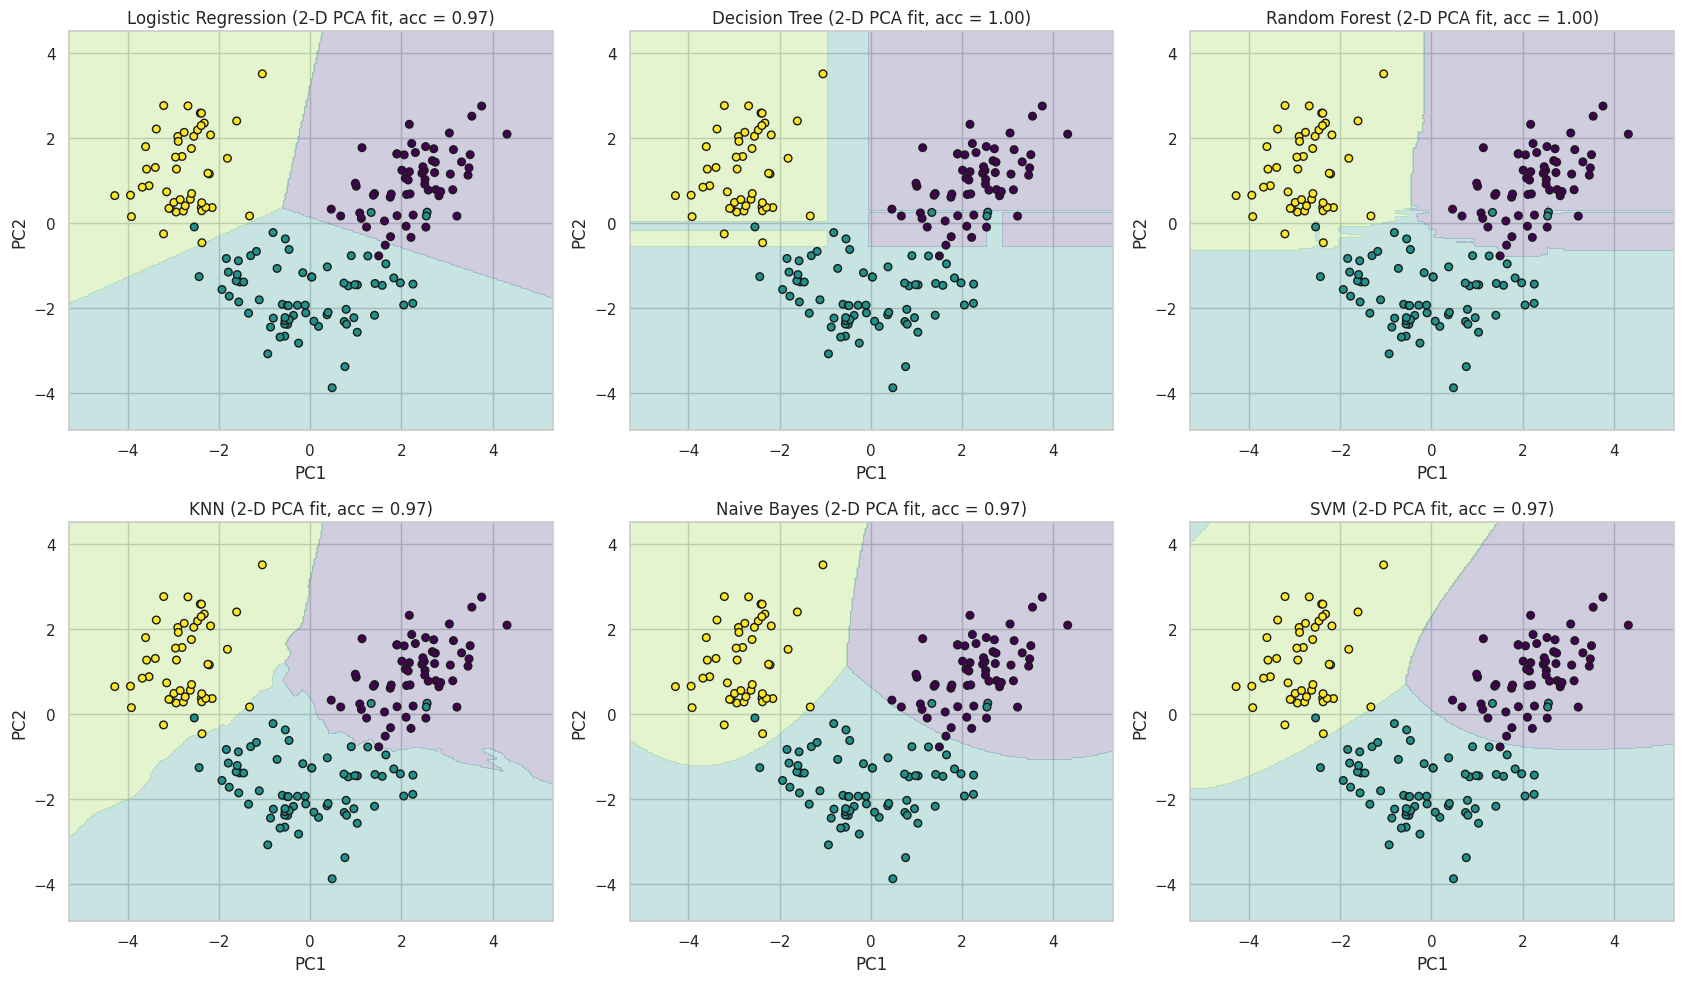

In [18]:
from sklearn.base import clone

x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (name, (model, _)) in zip(axes.ravel(), models.items()):
    m2d = clone(model).fit(X_pca, y)
    zz = m2d.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="viridis", levels=[-0.5, 0.5, 1.5, 2.5])
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", edgecolor="k", s=30)
    ax.set_title(f"{name} (2-D PCA fit, acc = {m2d.score(X_pca, y):.2f})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

SUMMARY OF  THE RESULTS
### Which performed best and why?

**On the single test split, Random Forest was best** (100%, zero errors). Logistic Regression, SVM, KNN and Naive Bayes each made exactly one mistake (97.2%), and the Decision Tree made two (94.4%).

**On cross-validation, Logistic Regression and SVM edge ahead** (98.3%). Random Forest drops to 97.8%. The top five models are within about one percentage point of each other, which is smaller than the fold-to-fold standard deviation (≈1–3 points). So **the honest conclusion is that the five leading models are statistically very close**; the Random Forest's perfect test score is partly luck of the split, and no model can be declared the clear winner on this dataset.

**Why the top models do so well**
- The classes are strongly separable: a few chemical features (flavanoids, proline, colour intensity) differ a lot between cultivars, so even simple linear boundaries work. That is why **Logistic Regression and SVM** are at or near the top.
- **Scaling** lets Logistic Regression, SVM and KNN use all 13 features fairly rather than being dominated by `proline` and `magnesium`.
- **Random Forest** averages many trees, which captures any non-linear structure and reduces variance, so it is robust and needs no scaling.
- **Naive Bayes** does surprisingly well despite its independence assumption being violated by correlated features, because the class-wise feature distributions are fairly Gaussian and well separated.
- **KNN** is solid but slightly behind, since with 13 dimensions and only ~140 training points, neighbourhoods are a little noisy and it is sensitive to the choice of k.

**Why the Decision Tree is weakest**
A single unpruned tree is a high-variance model: it fits the training data almost perfectly and small changes in the data change its splits. This shows in its CV score (89.3%) and the largest spread across folds. Combining many trees (Random Forest) fixes this, lifting accuracy by roughly 8 points.

**Caveats**
- Wine is a small, clean, easy dataset, so results will not necessarily carry over to harder problems.
- We used mostly default hyperparameters. Tuning (e.g. `GridSearchCV` for SVM's `C`/`gamma`, KNN's `k`, tree depth) could shift the ranking slightly.

**Bottom line:** For this dataset, Logistic Regression and SVM are the best choices overall (simple, fast, most consistent), Random Forest is an equally strong and robust alternative, and the single Decision Tree is the one clearly weaker option.

### Bonus: what drives the Random Forest's decisions?

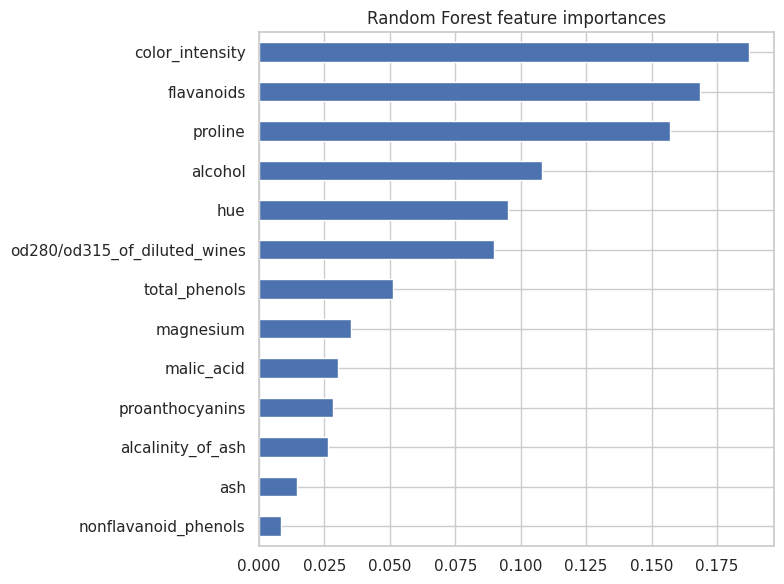

In [19]:
rf = models["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=wine.feature_names).sort_values()
imp.plot.barh(figsize=(8, 6), title="Random Forest feature importances")
plt.tight_layout()
plt.show()